# TP2 : extraction d'information, année 1945

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"   # doit venir avant tout import de numpy

import re, random
from collections import Counter, defaultdict

year = 1945
txt_path = "../../data/txt/"
files = sorted(f for f in os.listdir(txt_path)
               if f.endswith(".txt") and f"_{year}-" in f)

textes = {}
for f in files:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        textes[f] = fh.read()

def page(f):
    return f.split("_")[-1][:-4].split("-")[1]

p12 = [f for f in files if page(f) in ("00001", "00002")]
print(len(files), "fichiers,", len(p12), "pages 1 et 2")

100 fichiers, 65 pages 1 et 2


In [2]:
import os

year = 1945
txt_path = "../../data/txt/"

tous = [f for f in os.listdir(txt_path) if f.endswith(".txt")]
files = sorted(f for f in tous if f"_{year}-" in f)

print(len(tous), "fichiers dans le corpus")
print(len(files), "fichiers pour", year)
print(files[:5])

7936 fichiers dans le corpus
100 fichiers pour 1945
['KB_JB838_1945-01-06_01-00004.txt', 'KB_JB838_1945-01-13_01-00001.txt', 'KB_JB838_1945-03-23_01-00002.txt', 'KB_JB838_1945-04-02_01-00003.txt', 'KB_JB838_1945-04-03_01-00002.txt']


In [3]:
from collections import Counter

textes = {}
for f in files:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        textes[f] = fh.read()

mots = {f: len(t.split()) for f, t in textes.items()}
print(sum(mots.values()), "mots au total")
print("médiane :", sorted(mots.values())[len(mots) // 2], "mots par fichier")
print("le plus long :", max(mots, key=mots.get), max(mots.values()), "mots")

par_mois = Counter(f.split("_")[2][5:7] for f in files)
print("fichiers par mois :", sorted(par_mois.items()))

807577 mots au total
médiane : 8636 mots par fichier
le plus long : KB_JB838_1945-11-07_01-00004.txt 13491 mots
fichiers par mois : [('01', 2), ('03', 1), ('04', 8), ('05', 6), ('06', 12), ('07', 10), ('08', 14), ('09', 10), ('10', 9), ('11', 9), ('12', 19)]


In [4]:
import yake
from collections import defaultdict

kw_extractor = yake.KeywordExtractor(lan="fr", n=2, top=30)
compteur = Counter()
scores = defaultdict(list)

for f, text in textes.items():
    for kw, score in kw_extractor.extract_keywords(text):
        if len(kw.split()) == 2:
            compteur[kw.lower()] += 1
            scores[kw.lower()].append(score)

for kw, n in compteur.most_common(30):
    moyenne = sum(scores[kw]) / len(scores[kw])
    print(f"{kw:35} {n:3} docs   score moyen {moyenne:.4f}")

agence rossel                        31 docs   score moyen 0.0085
l’agence rossel                      16 docs   score moyen 0.0148
bon état                             13 docs   score moyen 0.0182
journal quotidien                    13 docs   score moyen 0.0434
van acker                            10 docs   score moyen 0.0241
ecrire agence                         9 docs   score moyen 0.0216
rue royale                            9 docs   score moyen 0.0264
quotidien prix                        8 docs   score moyen 0.0504
bruxelles dem                         6 docs   score moyen 0.0214
bonne maison                          6 docs   score moyen 0.0089
vente publique                        6 docs   score moyen 0.0076
rue neuve                             5 docs   score moyen 0.0333
soir illustré                         5 docs   score moyen 0.0666
rendus rédaction                      5 docs   score moyen 0.0417
prisonnier politique                  5 docs   score moyen 0.0188
belle mais

In [5]:
f = files[0]
print(f)
print(len(textes[f].split()), "mots")
print(textes[f][:1500])

KB_JB838_1945-01-06_01-00004.txt
12282 mots
KBDD envir. Bourse. 1 er janv. sent homme en peau brun, fourré, main gauche. Rapporter, 18, r. des Commercante, bonne réeomp> 27821 PERDE jeudi ' 28 entre 11 h. et midi, Bourse - Nord, mont.-brai dame or. Souvenir fam.* Bapp. c. b. récomp. & Mme Moucheur, 67, r. Pacification, apr. I9h. 27882 12 34 dée. apr.-midl a paquet confié à chanff. a été enlevé de sa voit, arrêtée r. du Commerce. La per», euscept. restlt. paquet peut s’adr.chauf- feur respons.: 50, aven. Princesse Elisateth, 50, Schaerbeek. Discret, et bonne récomp. 27274 PERDU trousseau clefs r. Fœsé aux Loups, arr. tram, 100 fr. récomp. COENE, 51, chaussée de Haecht, Sch. 28153 PERDU 29 dée. porte- monnaie homi cuir brun cont. 50 fr. médailles + 1 gros Penny angl. souv. bon. réc. Barwltz, 7, r. de "la Madeleine. 28240 PERDU tram SS, 30 déc. vers midi, valiæ conten. argent et trousse étud. médecine. Rapport. 16. r. du Pinson, Boitsfort. Récompense. 28151 TROUVE 15 chiens; 4 chats. Asil

In [6]:
import time, yake
kw_extractor = yake.KeywordExtractor(lan="fr", n=2, top=30)
t0 = time.time()
for f in files[:5]:
    kw_extractor.extract_keywords(textes[f])
print(round(time.time() - t0, 1), "secondes pour 5 fichiers")

10.6 secondes pour 5 fichiers


In [7]:
import yake
from collections import Counter, defaultdict

kw_extractor = yake.KeywordExtractor(lan="fr", n=2, top=30)

resultats = {}
for f, text in textes.items():
    resultats[f] = [(kw.lower(), s)
                    for kw, s in kw_extractor.extract_keywords(text)
                    if len(kw.split()) == 2]

print("extraction terminée :", len(resultats), "fichiers")

extraction terminée : 100 fichiers


In [8]:
def page(f):
    return f.split("_")[-1][:-4].split("-")[1]

def afficher(fichiers, titre, n=20):
    c, sc = Counter(), defaultdict(list)
    for f in fichiers:
        for kw, s in resultats[f]:
            c[kw] += 1
            sc[kw].append(s)
    print(f"--- {titre} ({len(fichiers)} fichiers) ---")
    for kw, nb in c.most_common(n):
        print(f"{kw:35} {nb:3} docs   score moyen {sum(sc[kw])/len(sc[kw]):.4f}")
    print()

afficher(files, "Toutes les pages")
afficher([f for f in files if page(f) in ("00001", "00002")], "Pages 1 et 2")
afficher([f for f in files if page(f) not in ("00001", "00002")], "Autres pages")

--- Toutes les pages (100 fichiers) ---
agence rossel                        31 docs   score moyen 0.0085
l’agence rossel                      16 docs   score moyen 0.0148
bon état                             13 docs   score moyen 0.0182
journal quotidien                    13 docs   score moyen 0.0434
van acker                            10 docs   score moyen 0.0241
ecrire agence                         9 docs   score moyen 0.0216
rue royale                            9 docs   score moyen 0.0264
quotidien prix                        8 docs   score moyen 0.0504
bruxelles dem                         6 docs   score moyen 0.0214
bonne maison                          6 docs   score moyen 0.0089
vente publique                        6 docs   score moyen 0.0076
rue neuve                             5 docs   score moyen 0.0333
soir illustré                         5 docs   score moyen 0.0666
rendus rédaction                      5 docs   score moyen 0.0417
prisonnier politique                

In [9]:
bruit = {"rossel", "agence", "quotidien", "journal", "rue", "écrire", "rédaction",
         "illustré", "prix", "bon", "bonne", "belle", "vente", "gages", "demande",
         "maison", "importante", "firme", "état", "royale", "neuve", "rendus"}

def afficher_filtre(fichiers, titre, n=25):
    c, sc = Counter(), defaultdict(list)
    for f in fichiers:
        for kw, s in resultats[f]:
            if any(m in bruit for m in kw.replace("'", " ").split()):
                continue
            c[kw] += 1
            sc[kw].append(s)
    print(f"--- {titre} ({len(fichiers)} fichiers) ---")
    for kw, nb in c.most_common(n):
        print(f"{kw:35} {nb:3} docs   score moyen {sum(sc[kw])/len(sc[kw]):.4f}")
    print()

p12 = [f for f in files if page(f) in ("00001", "00002")]
autres = [f for f in files if page(f) not in ("00001", "00002")]
afficher_filtre(p12, "Pages 1 et 2, bruit filtré")
afficher_filtre(autres, "Autres pages, bruit filtré")

--- Pages 1 et 2, bruit filtré (65 fichiers) ---
van acker                            10 docs   score moyen 0.0241
prisonnier politique                  5 docs   score moyen 0.0188
affaires étrangères                   5 docs   score moyen 0.0288
maréchal montgomery                   3 docs   score moyen 0.0281
parti socialiste                      3 docs   score moyen 0.0147
général eisenhower                    3 docs   score moyen 0.0211
roi léopold                           3 docs   score moyen 0.0502
partis politiques                     3 docs   score moyen 0.0493
lieutenant général                    3 docs   score moyen 0.0425
van cauwelaert                        3 docs   score moyen 0.0266
gouvernement polonais                 2 docs   score moyen 0.0216
armée américaine                      2 docs   score moyen 0.0342
président roosevelt                   2 docs   score moyen 0.0096
francs français                       2 docs   score moyen 0.0832
alors qu’il                

In [10]:
import re
from spacy.lang.fr.stop_words import STOP_WORDS

texte_p12 = " ".join(textes[f] for f in p12)
tokens = re.findall(r"[a-zàâäçéèêëîïôöùûüÿœæ]{3,}", texte_p12.lower())

bruit_nuage = {"rue", "tél", "ecr", "écrire", "agence", "rossel", "journal", "quotidien",
               "prix", "bon", "bonne", "belle", "vente", "demande", "dem", "tient", "heu",
               "lieu", "maison", "van", "den", "der", "het", "place", "bruxelles"}

avant = Counter(t for t in tokens if t not in STOP_WORDS)
apres = Counter(t for t in tokens if t not in STOP_WORDS and t not in bruit_nuage)

print("AVANT :", avant.most_common(25))
print("APRÈS :", apres.most_common(25))

AVANT : [('été', 1312), ('rue', 1105), ('rossel', 921), ('bruxelles', 822), ('guerre', 771), ('van', 695), ('dem', 615), ('ministre', 532), ('pays', 525), ('gouvernement', 518), ('ans', 505), ('général', 505), ('belgique', 493), ('faire', 440), ('bien', 439), ('contre', 435), ('lieu', 428), ('tél', 424), ('ecr', 417), ('france', 408), ('part', 398), ('grand', 395), ('prix', 389), ('belge', 365), ('président', 357)]
APRÈS : [('été', 1312), ('guerre', 771), ('ministre', 532), ('pays', 525), ('gouvernement', 518), ('ans', 505), ('général', 505), ('belgique', 493), ('faire', 440), ('bien', 439), ('contre', 435), ('france', 408), ('part', 398), ('grand', 395), ('belge', 365), ('président', 357), ('grande', 353), ('mort', 346), ('cours', 341), ('soir', 335), ('temps', 331), ('fut', 329), ('allemagne', 328), ('ecrire', 327), ('politique', 323)]


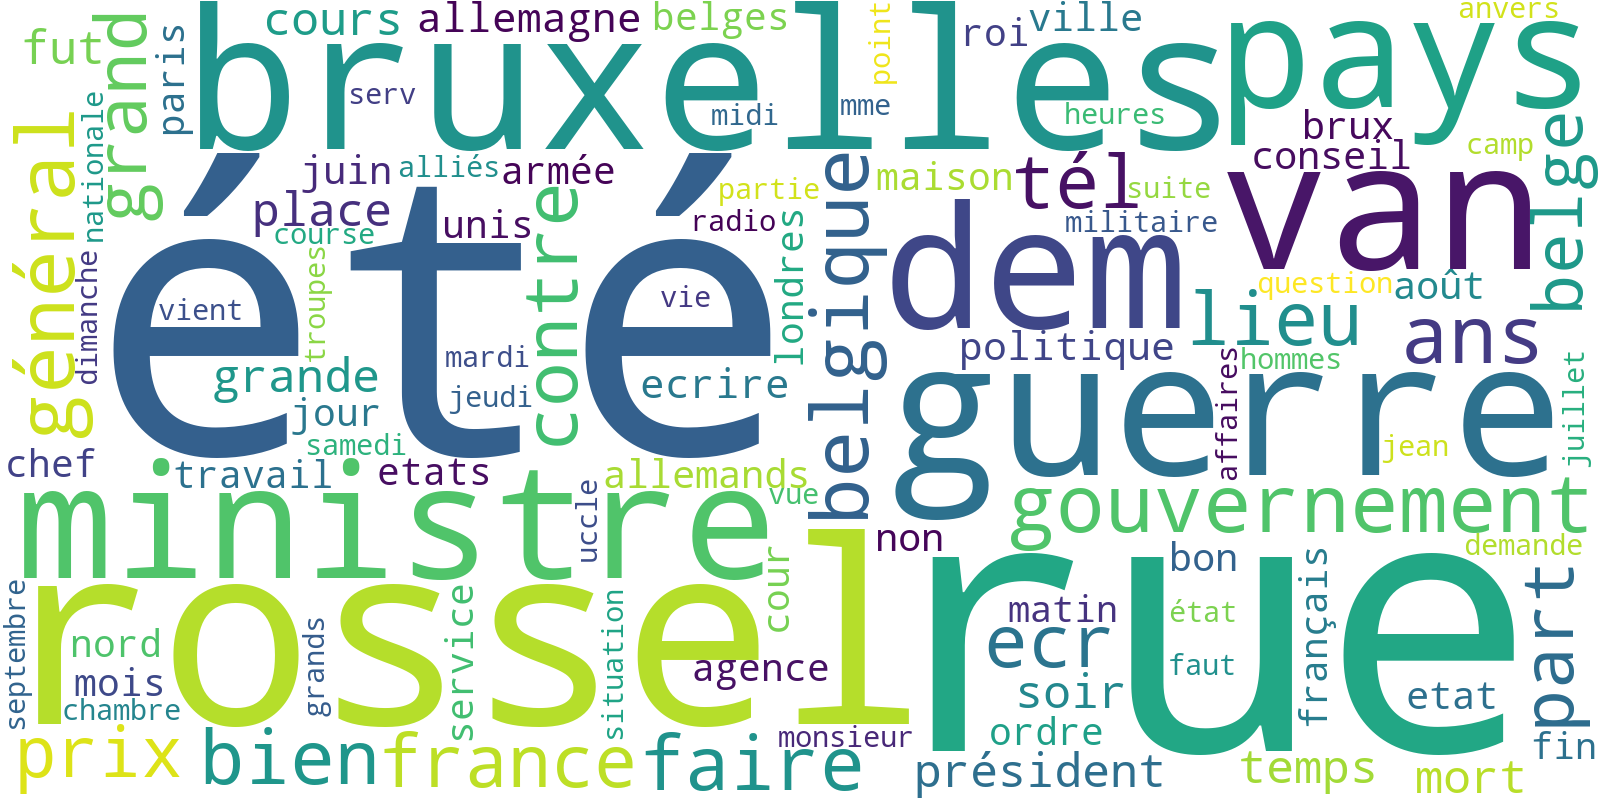

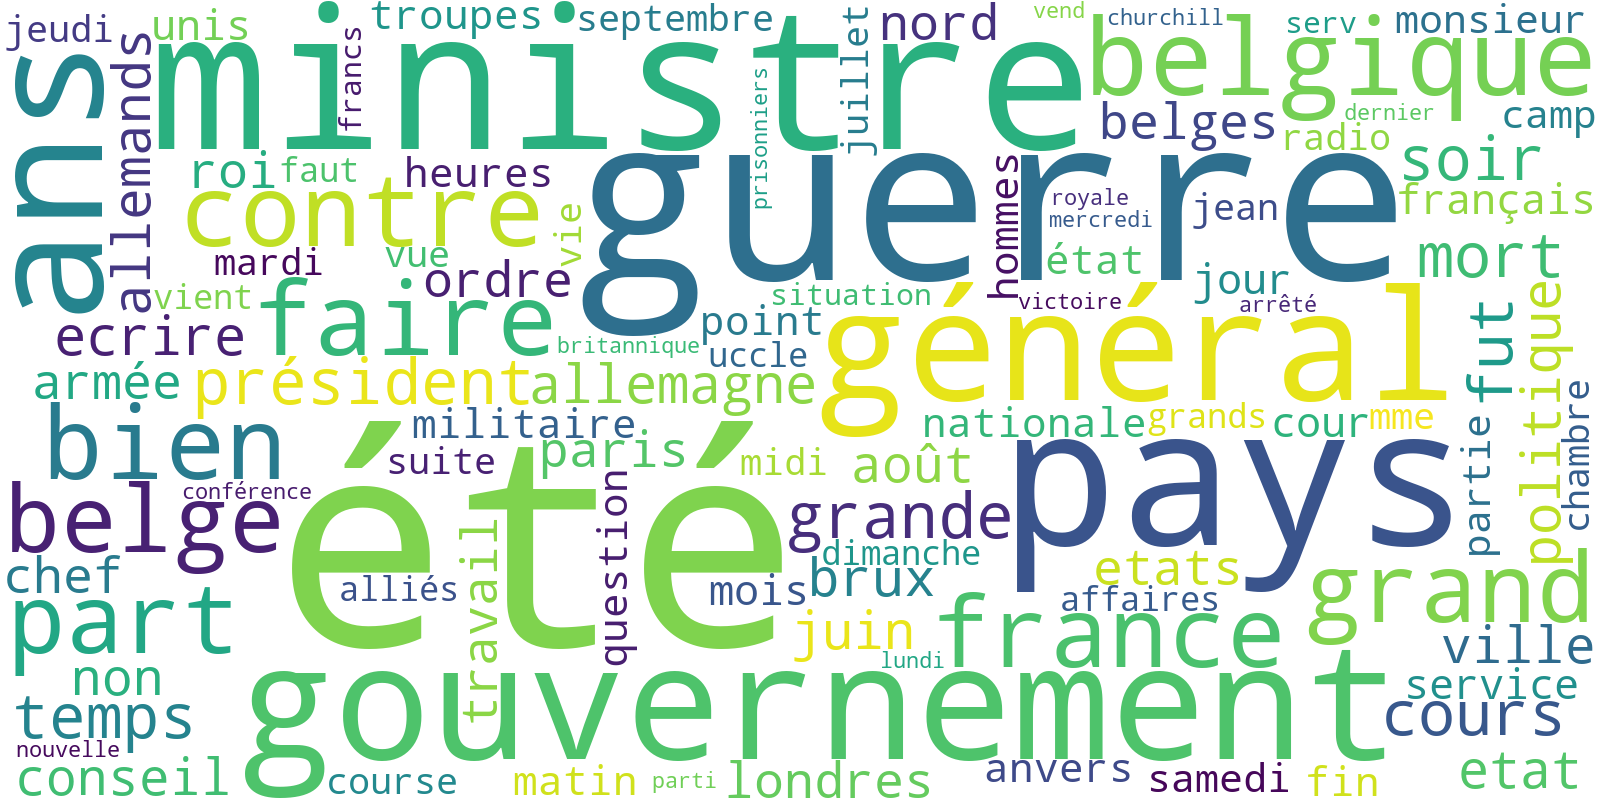

In [11]:
from wordcloud import WordCloud

for nom, freq in (("avant", avant), ("apres", apres)):
    nuage = WordCloud(width=1600, height=800, background_color="white",
                      max_words=100).generate_from_frequencies(freq)
    nuage.to_file(f"nuage_{nom}.png")

from IPython.display import Image, display
display(Image("nuage_avant.png"))
display(Image("nuage_apres.png"))

APRÈS 2 : [('guerre', 771), ('ministre', 532), ('pays', 525), ('gouvernement', 518), ('général', 505), ('belgique', 493), ('france', 408), ('belge', 365), ('président', 357), ('mort', 346), ('allemagne', 328), ('politique', 323), ('allemands', 313), ('etat', 302), ('ville', 296), ('conseil', 289), ('paris', 276), ('chef', 273), ('londres', 268), ('nord', 266), ('armée', 266), ('ordre', 263), ('etats', 258), ('belges', 256), ('roi', 253), ('travail', 249), ('français', 247), ('unis', 239), ('service', 236), ('cour', 233), ('question', 219), ('anvers', 218), ('hommes', 217), ('nationale', 212), ('troupes', 211), ('militaire', 208), ('état', 207), ('camp', 200), ('partie', 198), ('radio', 193)]


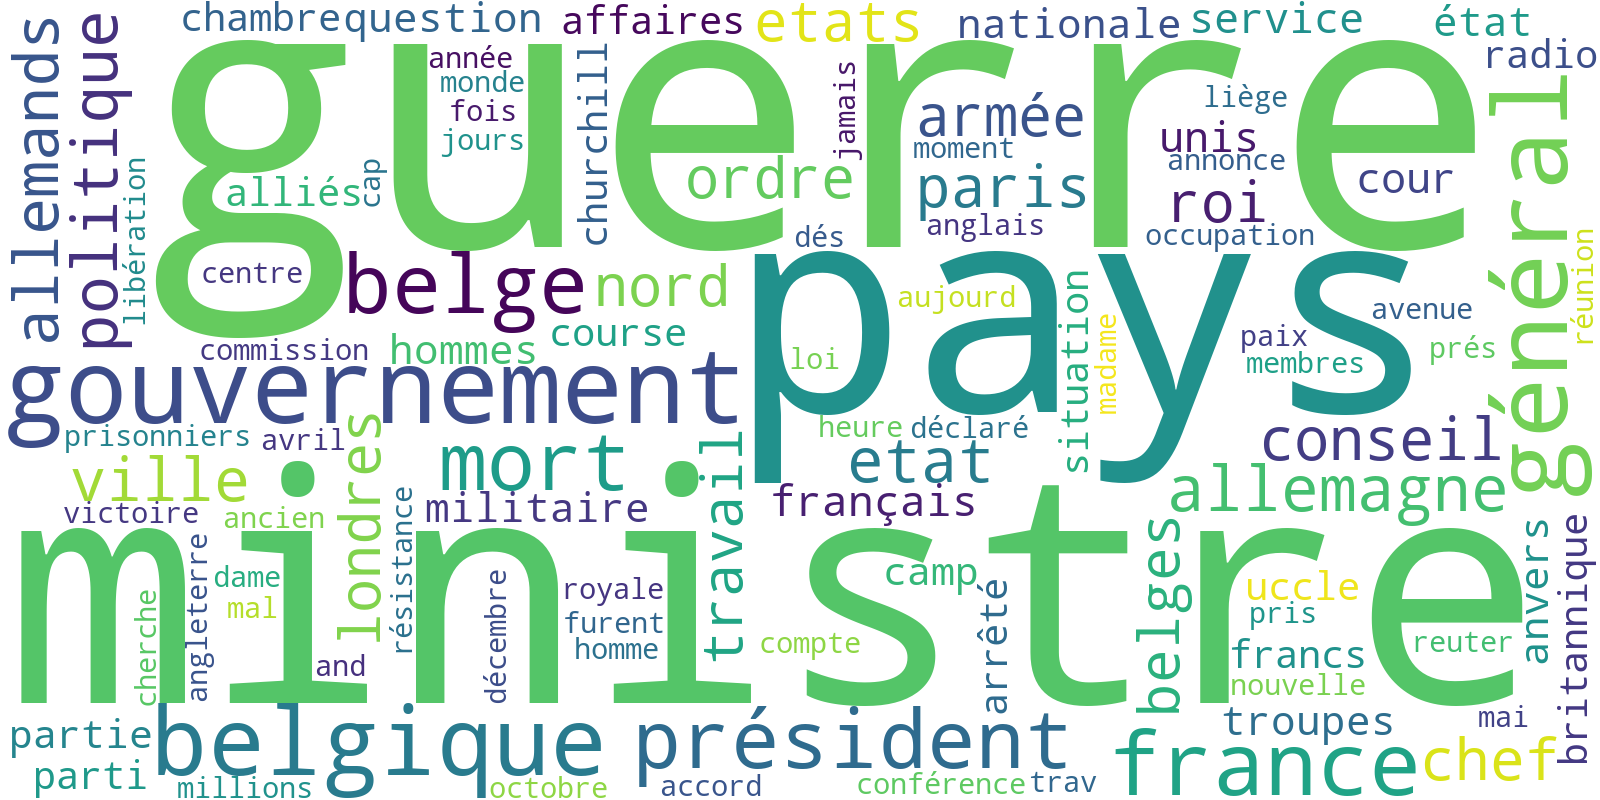

In [12]:
mots_outils = {"été", "fut", "faire", "bien", "contre", "part", "grand", "grande", "grands",
               "ans", "cours", "temps", "non", "fin", "vue", "suite", "point", "vie",
               "faut", "vient", "dernier", "ecrire", "ecr", "soir", "jour"}
calendrier = {"lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche",
              "matin", "midi", "heures", "mois", "juin", "juillet", "août", "septembre"}
bruit_2 = mots_outils | calendrier | {"brux", "mme", "monsieur", "jean", "serv", "vend"}

apres2 = Counter(t for t in tokens
                 if t not in STOP_WORDS and t not in bruit_nuage and t not in bruit_2)
print("APRÈS 2 :", apres2.most_common(40))

nuage = WordCloud(width=1600, height=800, background_color="white",
                  max_words=100).generate_from_frequencies(apres2)
nuage.to_file("nuage_apres_2.png")
display(Image("nuage_apres_2.png"))

In [13]:
import spacy

nlp = spacy.load("fr_core_news_md")   # remplace par le nom vu dans s3_ner.ipynb
print(nlp.pipe_names)
print(nlp.get_pipe("ner").labels)

disable = [p for p in ("parser", "lemmatizer", "morphologizer", "attribute_ruler")
           if p in nlp.pipe_names]

['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
('LOC', 'MISC', 'ORG', 'PER')


In [14]:
import time
t0 = time.time()
for doc in nlp.pipe((textes[f] for f in p12[:3]), batch_size=1, disable=disable):
    pass
print(round(time.time() - t0, 1), "secondes pour 3 pages")

10.2 secondes pour 3 pages


In [15]:
import os, re, time
from collections import Counter, defaultdict

year = 1945
txt_path = "../../data/txt/"
files = sorted(f for f in os.listdir(txt_path)
               if f.endswith(".txt") and f"_{year}-" in f)

textes = {}
for f in files:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        textes[f] = fh.read()

def page(f):
    return f.split("_")[-1][:-4].split("-")[1]

p12 = [f for f in files if page(f) in ("00001", "00002")]
print(len(files), "fichiers,", len(p12), "pages 1 et 2")

100 fichiers, 65 pages 1 et 2


In [16]:
cles = ["Van Acker", "Churchill", "Eisenhower", "Montgomery", "prisonnier",
        "Léopold", "gouvernement", "guerre"]
candidats = []
for f in p12:
    for s in re.split(r"(?<=[.!?])\s+", textes[f]):
        s = " ".join(s.split())
        if 12 <= len(s.split()) <= 40 and any(c in s for c in cles):
            candidats.append((f, s))

print(len(candidats), "phrases candidates")
random.seed(1945)
echantillon = random.sample(candidats, min(25, len(candidats)))
for i, (f, s) in enumerate(echantillon):
    print(i, f)
    print("   ", s)

1140 phrases candidates
0 KB_JB838_1945-11-16_02-00002.txt
    Churchill à Anvers Voici le programme de la visite officielle de M.
1 KB_JB838_1945-09-06_01-00001.txt
    * ¥ * A diverses reprises, le Parlement a accordé au gouvernement des pouvoirs extraordinaires ou spéciaux, lui délé gant le droit de faire les lois.
2 KB_JB838_1945-08-04_01-00002.txt
    Voltaire, Schaepbeek.53301 Marcel GRÜNER, né à Etterbèek le 17- 2-1922, prisonnier politique A.
3 KB_JB838_1945-09-05_01-00001.txt
    » ;Nieuw Vcrbond V.O.S.), de commémorer, le 2 septembre, leurs morts des deux guerres.
4 KB_JB838_1945-08-26_01-00001.txt
    Il y a lieu de noter qu’elle utilisait avant guerre 3.000 tonnes de papier par mcls et ou’ac- tucllement le contingent mis ‘à sa disposition atteint à peine 1.000 tonnes.
5 KB_JB838_1945-10-25_02-00001.txt
    » Mais il ajoute que « le seul espoir, pour l’humanité entière, réside dans un perfectionnement de la Charte des Nations Unies, qui en ferait un instrument de gouvernemen

In [17]:
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer
import pandas as pd

tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

def sentiment(phrase):
    pol, subj = tb(phrase).sentiment
    return round(pol, 3), round(subj, 3)

choix = [0, 3, 5, 8, 11, 14, 17, 19, 21, 24]  
phrases = [echantillon[i] for i in choix]

lignes = []
for n, (fichier, phrase) in enumerate(phrases, 1):
    pol, subj = sentiment(phrase)
    lignes.append({"n": n, "fichier": fichier, "phrase": phrase[:110],
                   "polarité": pol, "subjectivité": subj})

df = pd.DataFrame(lignes)
print(df.to_markdown(index=False))
print("Moyenne polarité :", round(df["polarité"].mean(), 3))
print("Moyenne subjectivité :", round(df["subjectivité"].mean(), 3))

|   n | fichier                          | phrase                                                                                                         |   polarité |   subjectivité |
|----:|:---------------------------------|:---------------------------------------------------------------------------------------------------------------|-----------:|---------------:|
|   1 | KB_JB838_1945-11-16_02-00002.txt | Churchill à Anvers Voici le programme de la visite officielle de M.                                            |      0     |          0     |
|   2 | KB_JB838_1945-09-05_01-00001.txt | » ;Nieuw Vcrbond V.O.S.), de commémorer, le 2 septembre, leurs morts des deux guerres.                         |      0     |          0     |
|   3 | KB_JB838_1945-10-25_02-00001.txt | » Mais il ajoute que « le seul espoir, pour l’humanité entière, réside dans un perfectionnement de la Charte d |      0.037 |          0.1   |
|   4 | KB_JB838_1945-07-24_01-00002.txt | Ici’ également, il- faudra 

Polarité moyenne : 0,02 ; subjectivité moyenne : 0,065 (voir tableau 4 du rapport).
